In [21]:
import os
import subprocess

import docx
import pdfplumber

from dotenv import load_dotenv
from google import genai
from google.genai import types

from langchain_core.messages import HumanMessage, SystemMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.tools import tool

from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.graph import START,END, MessagesState, StateGraph
from langgraph.prebuilt import tools_condition

from langsmith import traceable

from IPython.display import Image, display, Markdown


In [23]:
load_dotenv()
client = genai.Client()

In [24]:
PROMPT_TEMPLATE = """
You are a helpful tool that visits the following job posting and carefully reads its contents.
Summarize the key details in a clear and concise format, including:
Visit the provided job posting link, read it thoroughly, and extract and summarize all key information. Include:
- Job title
- Company name
- Location
- Employment type (full-time, part-time, contract, etc.)
- Salary or compensation (if available)
- Required qualifications/skills
- Primary responsibilities
- Benefits offered
- Application instructions
- Posting date (if available)

Format
- Respond with a clear, structured bullet-point list.
- Use exact factual information from the posting, no rewording beyond making it concise.
- If the posting is missing, inaccessible, or contains no job details, respond with:
"Job posting unavailable or contains no job details."

Do's
- Ensure all extracted details are accurate and directly taken from the posting.
- Keep descriptions short, professional, and easy to scan.
- Use consistent formatting for all fields (e.g., "Job Title: …").

Don'ts
- Do not include filler language, speculation, or personal opinions.
- Do not rewrite or interpret details—only report factual information from the posting.
"""


@tool
def job_posting_tool(job_link: str) -> str:
    """Extracts structured information from a job posting at the provided URL.

    Args:
        job_link (str): The URL of the job posting.

    Returns:
        str: A structured summary of the job posting's key details.
    """
    response = client.models.generate_content(
        model="gemini-3.5-flash-lite",
        contents=f"{PROMPT_TEMPLATE}\n\nVisit this job posting and extract details:\n{job_link}",
        config=types.GenerateContentConfig(
            tools=[types.Tool(url_context=types.UrlContext)],
        ),
    )
    return response.text or "Job posting unavailable or contains no job details."

In [25]:
@tool
def extract_cv_text(file_path: str) -> str:
    """Extracts the text content from a CV file in PDF, DOCX, or DOC format.
    The CV should be inside the same folder that this notebook is in.

    Args:
        file_path (str): The local file path or filename to the CV document.

    Returns:
        str: The extracted plain text from the CV, or an error message if
        the format is unsupported or cannot be read.
    """
    if not os.path.exists(file_path):
        return f"File not found: {file_path}"

    ext = os.path.splitext(file_path)[1].lower()

    if ext == ".docx":
        try:
            doc = docx.Document(file_path)
            return "\n".join(para.text for para in doc.paragraphs if para.text.strip())
        except Exception as e:
            return f"Error reading the .docx file: {e}"

    elif ext == ".pdf":
        try:
            pages_text = []
            with pdfplumber.open(file_path) as pdf:
                for page in pdf.pages:
                    page_text = page.extract_text()
                    if page_text:
                        pages_text.append(page_text)
            return "\n".join(pages_text)
        except Exception as e:
            return f"Error reading the .pdf file: {e}"

    elif ext == ".doc":
        try:
            out_dir = os.path.dirname(os.path.abspath(file_path))
            converted_path = os.path.join(
                out_dir, os.path.splitext(os.path.basename(file_path))[0] + ".docx"
            )
            subprocess.run(
                [
                    "soffice",
                    "--headless",
                    "--convert-to",
                    "docx",
                    "--outdir",
                    out_dir,
                    os.path.abspath(file_path),
                ],
                check=True,
            )
            doc = docx.Document(converted_path)
            text = "\n".join(para.text for para in doc.paragraphs if para.text.strip())
            if os.path.exists(converted_path):
                os.remove(converted_path)
            return text
        except Exception as e:
            return f"Error reading .doc file: {e}"

    else:
        return "Unsupported file format. Please use .pdf, .docx, or .doc."

In [26]:
tools = [job_posting_tool, extract_cv_text]
tool_node = ToolNode(tools=tools)

In [27]:
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")
llm_with_tools = llm.bind_tools(tools)

In [28]:


sys_msg = SystemMessage(content="""
You are an expert career assistant that helps the user with questions related to jobs, careers, and applications.

Your key capabilities:
- You have access to the user's CV and can read its contents using the `extract_cv_text` tool.
- You can look up and extract details from job postings using the `job_posting_tool`.
- You can compare the user's CV against one or more job postings to determine suitability and provide tailored advice.
- You can suggest improvements to the CV for better alignment with target roles.

When answering:
1. First, think step-by-step about the user's request.
2. If the task requires reading the CV, call the CV extraction tool before answering.
3. If the task involves evaluating job postings, call the job posting tool to gather accurate information before answering.
4. Compare and reason about the information before providing your final response.

Response format:
- Be clear, concise, and structured with bullet points or numbered lists.
- Use section headers when possible (e.g., "Strengths", "Weaknesses", "Recommendations").
- Support your statements with evidence from the CV or job postings.
- Avoid vague language—be specific and factual.

Constraints:
- Do not invent or guess details about the user's experience or job postings.
- Only use information available in the CV, job postings, or provided context.
- Keep your tone professional, friendly, and supportive.


""")

In [29]:
MODELS = [
   "gemini-3.1-flash-lite",    
   "gemini-3.5-flash-lite",
   "gemini-3.6-flash",
   "gemini-3.8-flash",
]


def invoke_with_model_fallback(messages, tools_list=None):
   last_error = None
   for model_name in MODELS:
      try:
         model = ChatGoogleGenerativeAI(
            model=model_name,
            timeout=15,
            max_retries=1,
         )
         runnable = model.bind_tools(tools_list) if tools_list else model
         return runnable.invoke(messages)
      except Exception as e:
         last_error = e
         print(f"Model {model_name} failed, trying next... ({e})", flush=True)
   raise RuntimeError(f"All models failed. Last error: {last_error}")

@traceable(name="Job Matching Tool")
def assistant(state: MessagesState):
   response = invoke_with_model_fallback([sys_msg] + state["messages"], tools_list=tools)
   return {"messages": [response]}

In [30]:


builder = StateGraph(MessagesState)

builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", tools_condition)

builder.add_edge("tools", "assistant")
react_graph = builder.compile()

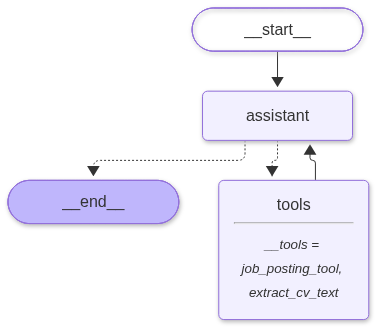

In [31]:
display(Image(react_graph.get_graph(xray=True).draw_mermaid_png()))

In [ ]:
config = {"configurable": {"thread_id": "1"}, "recursion_limit": 20}

In [ ]:
messages = [HumanMessage(content="""
        Can you take a look at my CV ath the location 'data/sample_cv.pdf'  and these 3 job applications and tell me whichone is the most suitable for my expiriance: 
        
        'https://techny.dev/jobs/forward-deployed-engineer-ai-arabicai-b7a8eb',
        'https://techny.dev/jobs/forward-deployed-software-engineer-arabicai-8e1a5a',
        'https://techny.dev/jobs/ai-ml-engineer-gsstech-group-91f1a5',
        'https://bbi.teamtailor.com/jobs/8746995-bi-intern',
        'https://careers.sdggroup.com/jobs/8777869-ai-llm-engineer-agentic-orchestration-langgraph?promotion=2307457-trackable-share-link-ai-llm-engineer-agentic-orchestration-langgraph'
        
        """)]

In [ ]:
result = react_graph.invoke({"messages": messages}, config)

In [ ]:
for m in result['messages']:
    m.pretty_print()

In [36]:
def extract_text(msg) -> str:
    content = getattr(msg, "content", msg)
    if isinstance(content, str):
        return content
    if isinstance(content, list):
        parts = []
        for block in content:
            if isinstance(block, str):
                parts.append(block)
            elif isinstance(block, dict) and block.get("text"):
                parts.append(block["text"])
            elif hasattr(block, "text") and block.text:
                parts.append(block.text)
        return "\n".join(parts)
    return str(content)

In [37]:
final_msg = result["messages"][-1]
display(Markdown(extract_text(final_msg)))

Based on your CV and the job postings provided, here is an analysis of your suitability and recommendations for your next steps.

### **Executive Summary**
You are a recent AI graduate (Class of 2026) with a strong foundation in **LLMs, RAG, and Agentic workflows**. 

*   **The "Best Fit" Match:** The **AI / LLM Engineer — Agentic Orchestration (LangGraph) role at SDG Group** is the most suitable position for your current experience level and specific technical focus. 
*   **The "Gap" Warning:** Note that several other roles you shared (e.g., Arabic.AI) explicitly require **7+ years of industry experience**. You are currently a junior-level candidate, so you should prioritize roles that emphasize "Intern," "Junior," or entry-level professional positions.

---

### **Detailed Evaluation**

#### **1. Top Recommendation: SDG Group (AI / LLM Engineer)**
*   **Why it fits:** This role aligns perfectly with your resume. You have explicitly listed **LangGraph, LLMs, RAG, and AI Agents** as your core skills, and your graduation project involved building an end-to-end Python pipeline—demonstrating the "real-world application" mindset they are looking for.
*   **Strength:** Unlike the senior roles, this position focuses on the specific technical stack (LangGraph) you are already highlighting.

#### **2. Potential Fit: GSSTech Group (AI/ML Engineer)**
*   **Why it fits:** This role requires 3+ years of experience, which is more accessible than the 7-year requirements of other roles. 
*   **Strength:** They are looking for experience with Python, TensorFlow, RAG, and vector databases—all of which are present in your CV. You would need to demonstrate that your academic projects and personal/freelance work have prepared you for "production" environments.

#### **3. Roles to Avoid (For Now)**
*   **Arabic.AI (Forward Deployed Engineer/Software Engineer):** Both roles at this company require **7+ years of experience** in software engineering or technical consulting. While your skills (Python, LLMs, APIs) are relevant, your current professional experience level does not meet their stated requirement for senior-level client-facing roles.
*   **BI Intern (BBI):** The job posting for this role was unavailable/invalid. Even if it were active, based on your current graduation date and focus on AI Agents, an "AI/LLM Engineer" role is a much better career move than a "BI Intern" role.

---

### **Recommendations for Your Applications**

1.  **Tailor your CV for the SDG Group Role:** 
    *   Highlight your graduation project more prominently. Explicitly mention that you engineered a "Python pipeline to ingest/parse data," which is highly relevant to their "orchestration layer" requirement.
    *   Emphasize your knowledge of "Human-in-the-loop" or "Evaluation frameworks" if you have any experience with them, as these are specific requirements in their job description.
2.  **Acknowledge your Junior Status:** When applying for roles that request 3+ years of experience (like GSSTech), use your cover letter to frame your graduation project and certifications (365 Data Science, Google AI) as "accelerated experience." Focus on the *depth* of your projects rather than the *number of years* spent in a corporate office.
3.  **Clean up your Links:** Ensure your GitHub link is updated with the code for your Graduation Project (Legal Case Knowledge Graph). Employers *will* click that link to see if you can actually code the production-grade systems they are hiring for.
4.  **Networking:** Since you are a junior candidate, applying through portals is difficult. Try to find a recruiter or team lead from **SDG Group** on LinkedIn and send a brief, professional note expressing your interest in the "Agentic Orchestration" role specifically.